# Bullet Brawl score model

The current Bullet Brawl Monte Carlo replays each player's past **scores**, weighted by the 0.96 weekly skill
decay. An arena score is roughly *games × points per game*, so that mixes two things that change at different
speeds:

- **Commitment** (when you join, how long you stay, how many games you play), which changes week to week.
- **Skill**, which changes slowly.

This notebook builds and tests the piece the new model needs: a function that predicts a player's **score
distribution** from their skill and their commitment:

$$\text{score} \sim f(\text{skill},\ \text{commitment},\ \text{field})$$

In the full model the Monte Carlo would draw each player's attendance and commitment from their recent history,
then draw a score from this function and rank everyone. Commitment is **given** here (the actual join time,
minutes and games), so this notebook tests only the score function.

**Sections**

1. Load the data and build features
2. Look at the data: is there a ladder effect, and how much does the rating leak?
3. The model specifications
4. Walk-forward evaluation: point accuracy, interval calibration, within-event ranking
5. Top-N probabilities when commitment is known: the score function inside a small Monte Carlo
6. A fair comparison with the current model, using only information available before the event
7. What the fitted function looks like
8. Findings

**A note on the comparisons.** Sections 4–5 compare specifications that are all given the *actual* commitment,
which isn't known before the event. That's the right test of the score function, but those numbers are not
comparable with the current model, which predicts without commitment. Section 6 makes the fair comparison.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.db import get_engine

pd.set_option('display.width', 160, 'display.max_columns', 40, 'display.max_rows', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

SEED = 42
rng_global = np.random.default_rng(SEED)

## 1. Load the data and build features

One row per player per event, from `bullet_brawl_standings`, keeping players who played at least one game.

Rows without game timestamps are dropped. That's 5 whole events scraped from standings pages, and a handful of
players elsewhere (usually 1–4 per event) whose games couldn't be matched. Section 5 treats the remaining
players of an event as its field, so those few missing players are a small source of error there.

**About `avg_rating`.** The ingester averages the player's **own** rating across their games in the event (the
`rating` field on their side of each game), so it isn't an opponent rating. That makes it a good skill proxy,
but it moves with the event's results, so it leaks a little. Before an event, the equivalent is the player's
current bullet rating from the chess.com API. Two versions are built:

| Feature | Meaning | Available before the event? |
|---|---|---|
| `rating_event` | average own rating during this event | approximately (mild leak, checked in section 2) |
| `rating_prev` | `avg_rating` at the player's previous Bullet Brawl | yes |

**Commitment features** (the actual values for this event):

| Feature | Meaning |
|---|---|
| `join_min` | minutes after the start of the player's first game ending |
| `minutes` | minutes between the player's first and last game endings |
| `games` | games played |

**History features** (from earlier events only, so no leakage):

| Feature | Meaning |
|---|---|
| `n_prior` | earlier Bullet Brawl appearances |
| `form_ppg` | decayed mean points per game in earlier events (0.96 per week) |
| `prev_minutes`, `avg_minutes` | minutes at the last appearance, and their decayed mean (0.75 per week) |
| `avg_join`, `avg_games` | decayed means of join time and games (0.75 per week) |

**Field features**, from the event's own players:

| Feature | Meaning |
|---|---|
| `n_players` | players in the event |
| `top10_rating` | mean `rating_event` of the event's 10 highest-rated players |
| `n_stronger_overlap` | players rated above this player whose time in the event overlapped theirs |

In [2]:
engine = get_engine()
raw = pd.read_sql('SELECT * FROM bullet_brawl_standings', engine)
tourn = pd.read_sql('SELECT tournament_slug, start_ts, finish_ts FROM bullet_brawl_tournaments', engine)

df = raw.merge(tourn, on='tournament_slug', how='inner')
df['date'] = pd.to_datetime(df['date'], utc=True).dt.tz_localize(None)
n_all = len(df)
df = df[df['games'] > 0]
n_played = len(df)
df = df.dropna(subset=['first_game_ts', 'last_game_ts', 'avg_rating'])
df = df[df['avg_rating'] > 1500]          # a few rows carry a nonsense rating
print(f'{n_all:,} rows → {n_played:,} with games → {len(df):,} with timestamps and rating; '
      f'{df.tournament_slug.nunique()} events, {df.username.nunique():,} players')

df['join_min'] = ((df['first_game_ts'] - df['start_ts']) / 60).clip(0, 120)
df['minutes']  = ((df['last_game_ts'] - df['first_game_ts']) / 60).clip(0, 121)
df['ppg']      = df['score'] / df['games']
df['rating_event'] = df['avg_rating']
df = df.sort_values(['date', 'rank']).reset_index(drop=True)

27,536 rows → 27,347 with games → 26,241 with timestamps and rating; 172 events, 2,983 players


In [3]:
def prior_features(df: pd.DataFrame) -> pd.DataFrame:
    """Per-row features from the same player's EARLIER events only."""
    out = {k: np.full(len(df), np.nan) for k in
           ('rating_prev', 'days_since_prev', 'n_prior', 'form_ppg',
            'prev_minutes', 'avg_minutes', 'avg_join', 'avg_games')}
    for _, g in df.groupby('username', sort=False):
        idx = g.index.to_numpy()
        t = (g['date'] - pd.Timestamp('2020-01-01')).dt.days.to_numpy() / 7      # weeks; unit-safe
        rating, ppg, mins, join, games = (g[c].to_numpy() for c in
                                          ('rating_event', 'ppg', 'minutes', 'join_min', 'games'))
        for j in range(len(idx)):
            out['n_prior'][idx[j]] = j
            if j == 0:
                continue
            weeks_ago = t[j] - t[:j]
            w_skill = 0.96 ** weeks_ago
            w_commit = 0.75 ** weeks_ago
            out['rating_prev'][idx[j]] = rating[j - 1]
            out['days_since_prev'][idx[j]] = weeks_ago[-1] * 7
            out['form_ppg'][idx[j]] = np.average(ppg[:j], weights=w_skill)
            out['prev_minutes'][idx[j]] = mins[j - 1]
            out['avg_minutes'][idx[j]] = np.average(mins[:j], weights=w_commit)
            out['avg_join'][idx[j]] = np.average(join[:j], weights=w_commit)
            out['avg_games'][idx[j]] = np.average(games[:j], weights=w_commit)
    return pd.DataFrame(out, index=df.index)


def field_features(df: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index, columns=['n_players', 'top10_rating', 'n_stronger_overlap'], dtype=float)
    for _, g in df.groupby('tournament_slug', sort=False):
        r = g['rating_event'].to_numpy()
        a, b = g['first_game_ts'].to_numpy(), g['last_game_ts'].to_numpy()
        overlap = (a[:, None] <= b[None, :]) & (a[None, :] <= b[:, None])
        stronger = r[None, :] > r[:, None]
        out.loc[g.index, 'n_players'] = len(g)
        out.loc[g.index, 'top10_rating'] = np.sort(r)[-10:].mean()
        out.loc[g.index, 'n_stronger_overlap'] = (overlap & stronger).sum(axis=1)
    return out


t0 = time.time()
df = df.join(prior_features(df)).join(field_features(df))
print(f'features built in {time.time() - t0:.0f}s')
df[['score', 'games', 'minutes', 'join_min', 'rating_event', 'rating_prev', 'n_prior', 'form_ppg',
    'avg_minutes', 'n_players', 'top10_rating', 'n_stronger_overlap']].describe().T.round(1)

features built in 4s


,count,mean,std,min,25%,50%,75%,max
score,26241.0,53.6,44.9,0.0,18.0,45.0,79.0,320.0
games,26241.0,39.3,24.2,1.0,17.0,39.0,63.0,109.0
minutes,26241.0,72.2,41.6,0.0,33.2,77.0,116.3,120.0
join_min,26241.0,15.8,25.4,0.0,1.9,2.4,18.4,120.0
rating_event,26241.0,2625.9,282.5,1509.0,2450.3,2624.3,2807.2,3454.3
rating_prev,23258.0,2632.9,280.8,1519.5,2456.7,2627.2,2812.2,3454.3
n_prior,26241.0,17.4,22.7,0.0,2.0,9.0,23.0,154.0
form_ppg,23258.0,1.3,0.5,0.0,0.9,1.2,1.6,3.8
avg_minutes,23258.0,75.6,34.6,0.0,47.1,80.9,109.1,120.0
n_players,26241.0,160.1,34.7,79.0,131.0,156.0,187.0,237.0


## 2. Look at the data

**The ladder effect.** If arena pairing really makes the extra games harder, points per game should *fall* as
games rise for players of the same rating, since a long session pushes you up the ladder into stronger
opponents. Quitting after losses pushes the other way: players on a bad night leave early with a low points per
game, which makes short sessions look worse.

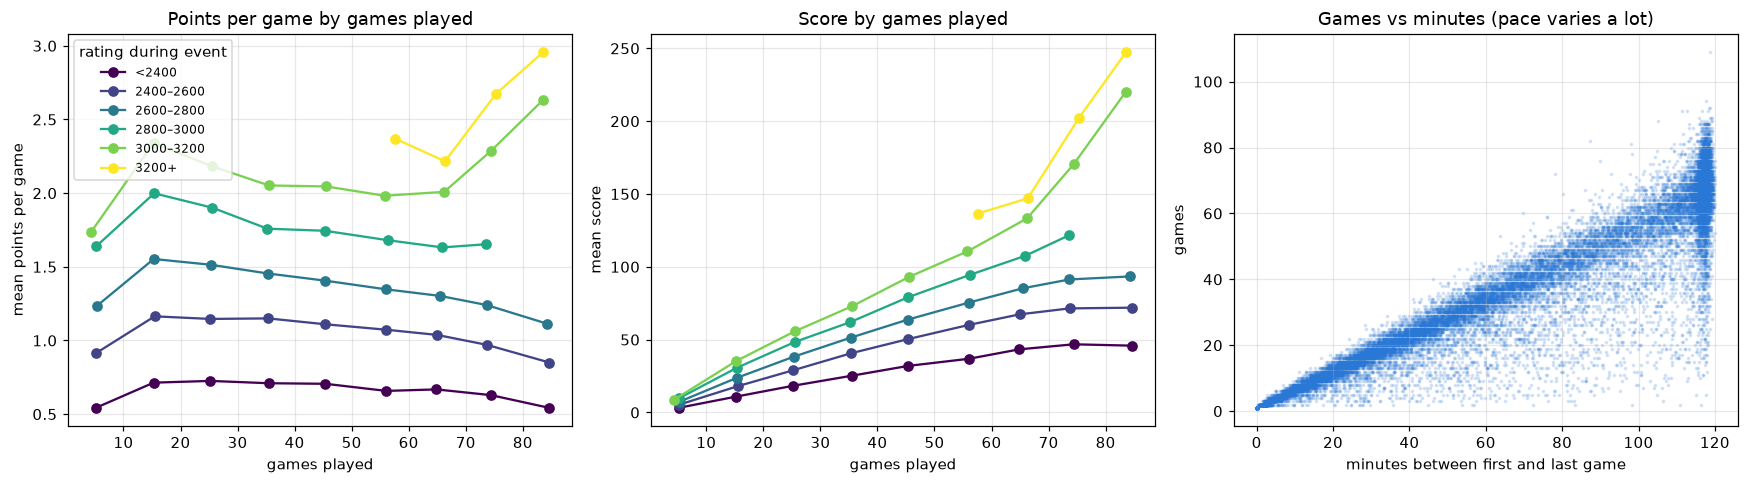

In [4]:
bins = [1500, 2400, 2600, 2800, 3000, 3200, 3600]
labels = ['<2400', '2400–2600', '2600–2800', '2800–3000', '3000–3200', '3200+']
df['rating_bin'] = pd.cut(df['rating_event'], bins, labels=labels)
df['games_bin'] = pd.cut(df['games'], [0, 10, 20, 30, 40, 50, 60, 70, 80, 120])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cmap = plt.get_cmap('viridis', len(labels))
for k, (lab, g) in enumerate(df.groupby('rating_bin', observed=True)):
    s = g.groupby('games_bin', observed=True).agg(ppg=('ppg', 'mean'), score=('score', 'mean'),
                                                   games=('games', 'mean'), n=('ppg', 'size'))
    s = s[s['n'] >= 20]
    axes[0].plot(s['games'], s['ppg'], 'o-', color=cmap(k), label=lab)
    axes[1].plot(s['games'], s['score'], 'o-', color=cmap(k), label=lab)
axes[0].set(xlabel='games played', ylabel='mean points per game', title='Points per game by games played')
axes[1].set(xlabel='games played', ylabel='mean score', title='Score by games played')
axes[0].legend(title='rating during event', fontsize=8)

axes[2].scatter(df['minutes'], df['games'], s=2, alpha=0.15, color='#2a78d6')
axes[2].set(xlabel='minutes between first and last game', ylabel='games',
            title='Games vs minutes (pace varies a lot)')
plt.tight_layout()
plt.show()

**How much does `rating_event` leak?** It's averaged over the event's own games, so a good night raises it. The
check: regress points per game on the previous-event rating, then see whether the rating *change* since then
explains what's left. Then compare how well each rating predicts points per game.

In [5]:
h = df.dropna(subset=['rating_prev']).copy()
h['rating_change'] = h['rating_event'] - h['rating_prev']
recent = h[h['days_since_prev'] <= 14]       # a short gap, so most of the change happened in this event
b = np.polyfit(recent['rating_prev'], recent['ppg'], 1)
resid = recent['ppg'] - np.polyval(b, recent['rating_prev'])
print(f'Rows with a previous appearance: {len(h):,}; within 14 days: {len(recent):,}')
print(f'Rating change since last event: median {h.rating_change.median():+.0f}, '
      f'IQR {h.rating_change.quantile(.25):+.0f} to {h.rating_change.quantile(.75):+.0f}')
print(f'corr(rating change, ppg left over after rating_prev), gap ≤ 14 days: '
      f'{np.corrcoef(recent.rating_change, resid)[0, 1]:.3f}')
print(f'corr(rating_event, ppg): {np.corrcoef(h.rating_event, h.ppg)[0, 1]:.3f}   '
      f'corr(rating_prev, ppg): {np.corrcoef(h.rating_prev, h.ppg)[0, 1]:.3f}')

Rows with a previous appearance: 23,258; within 14 days: 13,694
Rating change since last event: median +5, IQR -25 to +38
corr(rating change, ppg left over after rating_prev), gap ≤ 14 days: 0.269
corr(rating_event, ppg): 0.718   corr(rating_prev, ppg): 0.693


If that correlation is clearly positive, part of `rating_event`'s predictive power is the event's own results,
and models that use it will look somewhat better than they will be in production. The production input (the
live rating at bid time) falls between the two: fresher than `rating_prev`, without the leak of
`rating_event`. Section 4 fits both versions so the gap is visible.

## 3. Model specifications

Every specification is a set of **quantile regressions** (gradient-boosted trees, scikit-learn's
`HistGradientBoostingRegressor`) at the 5th, 25th, 50th, 75th and 95th percentiles. That gives a predicted
*distribution* for each player, which the Monte Carlo needs, especially its upper tail for the winner market.
Scores are constrained to rise with rating, games and minutes, which keeps the fit sensible where data is thin.
Trees handle the missing values that newcomers have for the history features.

| Spec | Skill | Commitment | History | Field |
|---|---|---|---|---|
| `games_only` | — | games | — | — |
| `rating_games` | `rating_event` | games | — | — |
| `rating_minutes` | `rating_event` | minutes, join time | — | — |
| `rating_all_commit` | `rating_event` | games, minutes, join time | — | — |
| `prev_all_commit` | `rating_prev` | games, minutes, join time | — | — |
| `form` | `rating_event` | games, minutes, join time | appearances, form | — |
| `field` | `rating_event` | games, minutes, join time | appearances, form | all three |

There's also `structural`, a hand-built model for reference: least squares on
`score = games × (b0 + b1·r + b2·r²) + games² × (b3 + b4·r)`, where `r` is the centred rating, with Gaussian
residuals whose spread grows with games. It's one interpretable formula against the trees.

Commitment can be represented by **games** (the simulation would draw games) or by **minutes** (it would draw
minutes and join time). Comparing `rating_games` with `rating_minutes` shows which works better.

In [6]:
QUANTILES = np.array([0.05, 0.25, 0.50, 0.75, 0.95])

SPECS = {
    'games_only':        ['games'],
    'rating_games':      ['rating_event', 'games'],
    'rating_minutes':    ['rating_event', 'minutes', 'join_min'],
    'rating_all_commit': ['rating_event', 'games', 'minutes', 'join_min'],
    'prev_all_commit':   ['rating_prev', 'games', 'minutes', 'join_min'],
    'form':              ['rating_event', 'games', 'minutes', 'join_min', 'n_prior', 'form_ppg'],
    'field':             ['rating_event', 'games', 'minutes', 'join_min', 'n_prior', 'form_ppg',
                          'n_players', 'top10_rating', 'n_stronger_overlap'],
}
MONOTONE = {'rating_event': 1, 'rating_prev': 1, 'games': 1, 'minutes': 1, 'n_stronger_overlap': -1}
HGB_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                  l2_regularization=1.0, random_state=SEED)


class QuantileModel:
    """One gradient-boosted regressor per quantile; predictions sorted so the quantiles never cross."""

    def __init__(self, features):
        self.features = features

    def fit(self, X: pd.DataFrame, y):
        mono = [MONOTONE.get(f, 0) for f in self.features]
        self.models = [HistGradientBoostingRegressor(loss='quantile', quantile=q, monotonic_cst=mono,
                                                     **HGB_PARAMS).fit(X[self.features], y)
                       for q in QUANTILES]
        return self

    def predict_quantiles(self, X: pd.DataFrame) -> np.ndarray:
        Q = np.column_stack([m.predict(X[self.features]) for m in self.models])
        return np.clip(np.sort(Q, axis=1), 0, None)


class StructuralModel:
    """score = games·(b0 + b1 r + b2 r²) + games²·(b3 + b4 r), with Gaussian residuals ∝ sqrt(games)."""

    def _design(self, X):
        g = X['games'].to_numpy(float)
        r = (X['rating_event'].to_numpy(float) - 2600) / 200
        return np.column_stack([g, g * r, g * r ** 2, g ** 2, g ** 2 * r])

    def fit(self, X, y):
        A = self._design(X)
        self.beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        resid = y - A @ self.beta
        self.scale = np.sqrt(np.mean(resid ** 2 / np.maximum(X['games'].to_numpy(float), 1)))
        return self

    def predict_quantiles(self, X):
        from scipy.stats import norm
        mu = self._design(X) @ self.beta
        sd = self.scale * np.sqrt(np.maximum(X['games'].to_numpy(float), 1))
        return np.clip(mu[:, None] + sd[:, None] * norm.ppf(QUANTILES)[None, :], 0, None)


def make_model(name):
    return StructuralModel() if name == 'structural' else QuantileModel(SPECS[name])


MODEL_NAMES = ['structural', *SPECS]

**Turning five quantiles into a distribution.** To sample, the predicted quantiles are joined into a piecewise
linear inverse CDF. Below the 5th and above the 95th percentile the outer segments' slopes continue to the 0th
and 100th, and scores are floored at 0. The tails are therefore bounded, which is a known simplification:
the very top of the distribution is somewhat understated.

In [7]:
_LEVELS = np.concatenate([[0.0], QUANTILES, [1.0]])


def extend_quantiles(Q: np.ndarray) -> np.ndarray:
    lo = Q[:, 0] - (Q[:, 1] - Q[:, 0]) * (QUANTILES[0] / (QUANTILES[1] - QUANTILES[0]))
    hi = Q[:, -1] + (Q[:, -1] - Q[:, -2]) * ((1 - QUANTILES[-1]) / (QUANTILES[-1] - QUANTILES[-2]))
    return np.column_stack([np.clip(lo, 0, None), Q, hi])


def sample_scores(Q: np.ndarray, u: np.ndarray) -> np.ndarray:
    """Q: players × 5 quantiles. u: sims × players uniforms. Returns sims × players scores."""
    E = extend_quantiles(Q)                                   # players × 7
    seg = np.clip(np.searchsorted(_LEVELS, u, side='right') - 1, 0, len(_LEVELS) - 2)
    cols = np.arange(Q.shape[0])[None, :]
    l0, l1 = _LEVELS[seg], _LEVELS[seg + 1]
    v0, v1 = E[cols, seg], E[cols, seg + 1]
    return v0 + (v1 - v0) * (u - l0) / (l1 - l0)

## 4. Walk-forward evaluation

Six folds, each a half-year (2024 H1 to 2026 H2). Every fold trains on **all events before it** and tests on
the events in it, so nothing is fitted on the future.

Metrics on the test rows:

- **MAE**: mean absolute error of the predicted median, in score points.
- **Pinball loss**: the standard score for quantile predictions, averaged over the five quantiles. Lower is
  better, and it rewards a well-shaped distribution, not just a good median.
- **90% coverage**: share of actual scores between the predicted 5th and 95th percentiles. It should be near
  0.90.
- **Spearman**: rank correlation between predicted median and actual score *within each event*, averaged over
  events. This is closest to what top-N markets need.

In [8]:
FOLDS = [(pd.Timestamp(f'{y}-{m:02d}-01'), pd.Timestamp(f'{y + (m == 7)}-{1 if m == 7 else 7:02d}-01'))
         for y in (2024, 2025, 2026) for m in (1, 7)]


def pinball(y, Q):
    d = y[:, None] - Q
    return np.mean(np.maximum(QUANTILES * d, (QUANTILES - 1) * d))


preds = {}                 # (model name) -> DataFrame of test rows with quantile columns
fold_rows = []
t0 = time.time()
for start, end in FOLDS:
    train = df[df['date'] < start]
    test = df[(df['date'] >= start) & (df['date'] < end)]
    if test.empty:
        continue
    for name in MODEL_NAMES:
        feats = ['rating_event', 'games'] if name == 'structural' else SPECS[name]
        tr = train.dropna(subset=['rating_prev']) if 'rating_prev' in feats else train
        model = make_model(name).fit(tr, tr['score'].to_numpy(float))
        Q = model.predict_quantiles(test)
        out = test[['tournament_slug', 'date', 'username', 'rank', 'score']].copy()
        out[[f'q{int(q * 100):02d}' for q in QUANTILES]] = Q
        preds.setdefault(name, []).append(out)
    fold_rows.append({'fold': f'{start:%Y-%m}', 'train_rows': len(train), 'test_rows': len(test),
                      'test_events': test.tournament_slug.nunique()})
preds = {k: pd.concat(v) for k, v in preds.items()}
print(f'fitted {len(MODEL_NAMES)} models × {len(fold_rows)} folds in {time.time() - t0:.0f}s')
pd.DataFrame(fold_rows)

fitted 8 models × 6 folds in 383s


,fold,train_rows,test_rows,test_events
0,2024-01,3579,3475,25
1,2024-07,7054,3620,25
2,2025-01,10674,4545,23
3,2025-07,15219,3690,26
4,2026-01,18909,4166,26
5,2026-07,23075,3166,17


In [9]:
QCOLS = [f'q{int(q * 100):02d}' for q in QUANTILES]


def summarize(p: pd.DataFrame) -> dict:
    y, Q = p['score'].to_numpy(float), p[QCOLS].to_numpy(float)
    rho = p.groupby('tournament_slug').apply(lambda g: spearmanr(g['q50'], g['score']).statistic,
                                              include_groups=False)
    return {'MAE': np.mean(np.abs(y - Q[:, 2])), 'pinball': pinball(y, Q),
            'coverage_90': np.mean((y >= Q[:, 0]) & (y <= Q[:, -1])), 'spearman': rho.mean()}


# prev_all_commit is scored only on rows that have a previous appearance; score the others on the same rows too.
has_prev = df.loc[df['rating_prev'].notna(), ['tournament_slug', 'username']]
summary = pd.DataFrame({name: summarize(p) for name, p in preds.items()}).T
summary_prev_rows = pd.DataFrame({name: summarize(p.merge(has_prev)) for name, p in preds.items()}).T
print('All test rows')
display(summary.round(3))
print('Only rows with a previous appearance (the rows prev_all_commit can score)')
display(summary_prev_rows.round(3))

All test rows


,MAE,pinball,coverage_90,spearman
structural,9.218,2.982,0.870,0.969
games_only,16.567,5.161,0.881,0.873
rating_games,8.543,2.674,0.847,0.969
rating_minutes,10.288,3.241,0.850,0.953
rating_all_commit,7.618,2.412,0.834,0.976
prev_all_commit,8.854,2.852,0.815,0.962
form,7.218,2.296,0.829,0.977
field,6.817,2.175,0.834,0.977


Only rows with a previous appearance (the rows prev_all_commit can score)


,MAE,pinball,coverage_90,spearman
structural,9.415,3.052,0.867,0.969
games_only,16.995,5.290,0.884,0.869
rating_games,8.695,2.721,0.850,0.969
rating_minutes,10.564,3.326,0.854,0.953
rating_all_commit,7.734,2.448,0.836,0.977
prev_all_commit,8.470,2.691,0.840,0.970
form,7.303,2.325,0.831,0.977
field,6.894,2.200,0.837,0.978


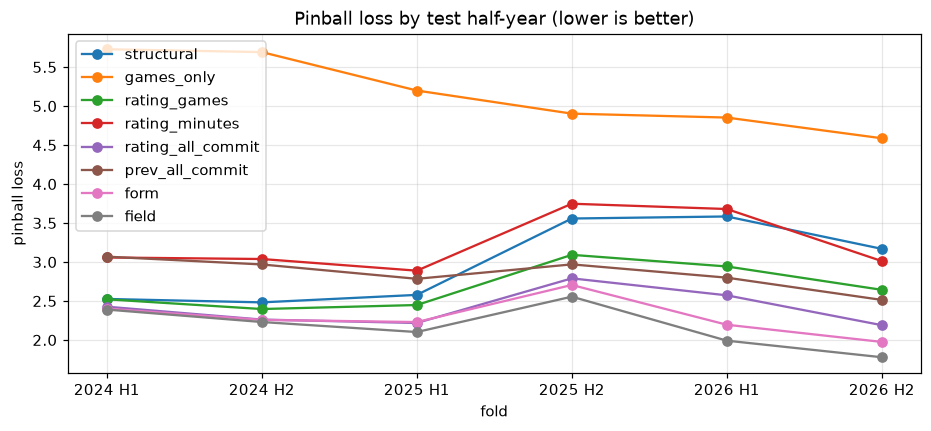

In [10]:
by_fold = pd.concat(
    {name: p.assign(fold=p['date'].dt.year.astype(str) + np.where(p['date'].dt.month < 7, ' H1', ' H2'))
            .groupby('fold').apply(lambda g: pinball(g['score'].to_numpy(float), g[QCOLS].to_numpy(float)),
                                   include_groups=False)
     for name, p in preds.items()}, axis=1)
ax = by_fold.plot(marker='o', figsize=(10, 4), title='Pinball loss by test half-year (lower is better)')
ax.set_ylabel('pinball loss')
plt.show()

## 5. Top-N probabilities when commitment is known

The markets pay on rank, not on score. For each test event, every model's predicted distributions go into a
small Monte Carlo (4,000 simulations): each simulation draws one score per player from their distribution and
ranks the field. That gives each player's probability of finishing in the top 1, 3, 5, 8 and 10, scored against
who actually did.

Attendance and commitment are the actual values, so this measures only how well the score function separates
players once you know who came and for how long. **These probabilities are sharper than any real pre-event
forecast can be**, so compare models with each other here, not with the current production model.

Scores: **log loss** and **Brier score**, both lower-is-better, summed over players and averaged over events.

In [11]:
N_VALUES = [1, 3, 5, 8, 10]
N_SIMS_EVAL = 4000


def topn_probs(Q: np.ndarray, rng) -> dict[int, np.ndarray]:
    n = Q.shape[0]
    u = rng.random((N_SIMS_EVAL, n))
    s = sample_scores(Q, u) + rng.random((N_SIMS_EVAL, n)) * 1e-3     # break exact ties at random
    order = np.argsort(-s, axis=1)
    rank = np.empty_like(order)
    rank[np.arange(N_SIMS_EVAL)[:, None], order] = np.arange(n)[None, :]
    return {k: (rank < k).mean(axis=0) for k in N_VALUES}


def score_topn(p_by_n: dict, actual_rank: np.ndarray) -> dict:
    out = {}
    for k in N_VALUES:
        p = np.clip(p_by_n[k], 1e-4, 1 - 1e-4)
        y = (actual_rank <= k).astype(float)
        out[f'logloss_top{k}'] = -np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
        out[f'brier_top{k}'] = np.sum((p - y) ** 2)
    return out


def evaluate_topn(pred_table: pd.DataFrame, seed=SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    rows = [score_topn(topn_probs(g[QCOLS].to_numpy(float), rng), g['rank'].to_numpy())
            for _, g in pred_table.groupby('tournament_slug')]
    return pd.DataFrame(rows).mean()


t0 = time.time()
topn = pd.DataFrame({name: evaluate_topn(p) for name, p in preds.items()}).T
print(f'{len(preds)} models scored in {time.time() - t0:.0f}s')
display(topn[[c for c in topn if c.startswith('logloss')]].round(3))
display(topn[[c for c in topn if c.startswith('brier')]].round(3))

8 models scored in 94s


,logloss_top1,logloss_top3,logloss_top5,logloss_top8,logloss_top10
structural,1.986,3.514,5.394,5.751,6.824
games_only,4.984,10.390,15.216,20.506,24.109
rating_games,2.357,3.970,5.691,6.091,7.039
rating_minutes,2.257,4.171,5.638,6.271,7.253
rating_all_commit,2.437,3.996,5.547,5.914,6.807
prev_all_commit,2.888,4.858,6.615,7.745,8.798
form,2.275,3.978,5.635,6.093,6.931
field,2.082,3.544,5.272,5.476,6.281


,brier_top1,brier_top3,brier_top5,brier_top8,brier_top10
structural,0.583,1.040,1.568,1.700,2.007
games_only,0.984,2.559,4.067,6.035,7.282
rating_games,0.718,1.232,1.743,1.865,2.131
rating_minutes,0.664,1.315,1.774,1.911,2.190
rating_all_commit,0.730,1.242,1.726,1.838,2.096
prev_all_commit,0.808,1.518,2.034,2.284,2.563
form,0.678,1.220,1.737,1.887,2.145
field,0.641,1.094,1.584,1.663,1.896


**Calibration check for the winner market.** Among players a model gave a given chance of winning, how often did
they win? Points on the diagonal mean the probabilities can be taken at face value.

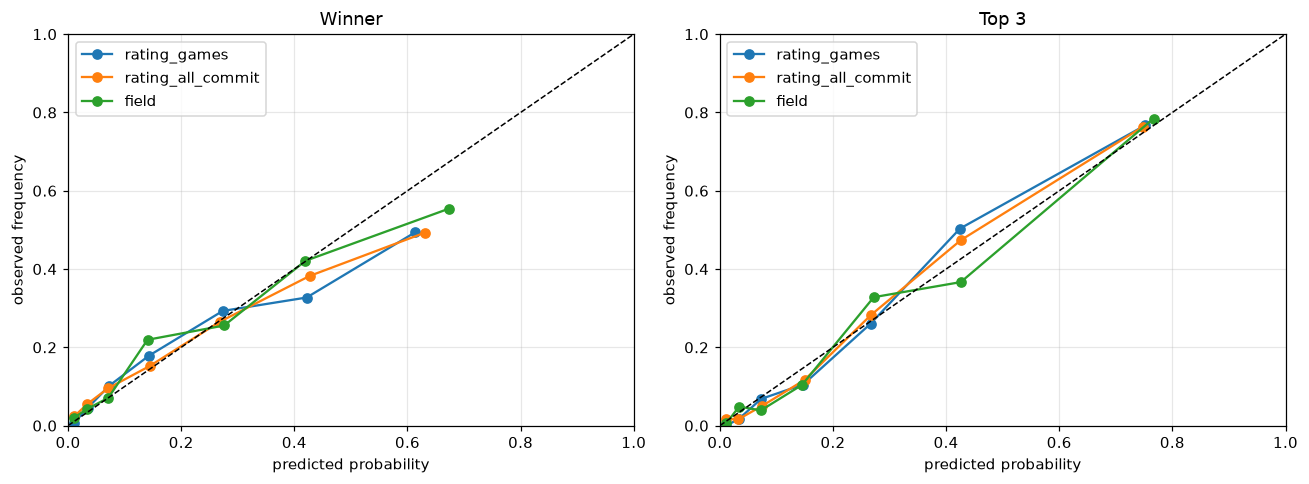

In [12]:
def winner_calibration(pred_table, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for _, g in pred_table.groupby('tournament_slug'):
        p = topn_probs(g[QCOLS].to_numpy(float), rng)
        rows.append(pd.DataFrame({'p': p[1], 'p3': p[3], 'won': g['rank'].to_numpy() == 1,
                                  'top3': g['rank'].to_numpy() <= 3}))
    return pd.concat(rows, ignore_index=True)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
edges = [0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0]
for name in ['rating_games', 'rating_all_commit', 'field']:
    c = winner_calibration(preds[name])
    for ax, pcol, ycol in [(axes[0], 'p', 'won'), (axes[1], 'p3', 'top3')]:
        sub = c[c[pcol] > 0.005]
        b = sub.groupby(pd.cut(sub[pcol], edges), observed=True).agg(
            pred=(pcol, 'mean'), actual=(ycol, 'mean'), n=(ycol, 'size'))
        ax.plot(b['pred'], b['actual'], 'o-', label=name)
for ax, title in zip(axes, ['Winner', 'Top 3']):
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set(xlabel='predicted probability', ylabel='observed frequency', title=title, xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()

## 6. A fair comparison with the current model

The current model predicts before the event, without knowing anyone's commitment. To compare fairly, both sides
get only information available beforehand, and both are scored on the same players: those who actually played,
with their actual ranks.

- **`current`**: the production approach. Each simulation picks one of the player's past scores, weighted by
  0.96 per week, and adds Gaussian noise of 10 points. Players with no history draw from the training
  folds' first-appearance scores.
- **`pre_event`**: a quantile model using only pre-event inputs: `rating_prev`, appearances, form, and the
  decayed history of minutes, join time and games. It predicts the score directly, so it isn't the planned
  two-stage model (draw commitment, then score). That has to wait for the commitment model, but this shows
  whether rating plus recent commitment already beats replaying old scores.

Both use the same folds as section 4.

In [ ]:
PRE_EVENT_FEATURES = ['rating_prev', 'days_since_prev', 'n_prior', 'form_ppg',
                      'prev_minutes', 'avg_minutes', 'avg_join', 'avg_games']
MONOTONE.update({'avg_minutes': 1, 'avg_games': 1})
SPECS_PRE = {'pre_event': PRE_EVENT_FEATURES}


def current_model_quantiles(train: pd.DataFrame, test: pd.DataFrame, rng, n_draws=4000) -> np.ndarray:
    """Quantiles of the current model's per-player score distribution, by sampling it."""
    newcomer_pool = train.loc[train['n_prior'] == 0, 'score'].to_numpy(float)
    hist = {u: g for u, g in train.groupby('username')}
    Q = np.empty((len(test), len(QUANTILES)))
    for i, (u, d) in enumerate(zip(test['username'], test['date'])):
        g = hist.get(u)
        g = None if g is None else g[g['date'] < d]
        if g is None or g.empty:
            draws = rng.choice(newcomer_pool, n_draws)
        else:
            w = 0.96 ** ((d - g['date']).dt.days.to_numpy() / 7)
            draws = rng.choice(g['score'].to_numpy(float), n_draws, p=w / w.sum())
        draws = draws + rng.normal(0, 10, n_draws)
        Q[i] = np.quantile(draws, QUANTILES)
    return np.clip(Q, 0, None)


fair = {}
rng = np.random.default_rng(SEED)
t0 = time.time()
for start, end in FOLDS:
    train = df[df['date'] < start]
    test = df[(df['date'] >= start) & (df['date'] < end)]
    if test.empty:
        continue
    base = test[['tournament_slug', 'date', 'username', 'rank', 'score']]
    m = QuantileModel(PRE_EVENT_FEATURES).fit(train, train['score'].to_numpy(float))
    fair.setdefault('pre_event', []).append(base.assign(**dict(zip(QCOLS, m.predict_quantiles(test).T))))
    fair.setdefault('current', []).append(
        base.assign(**dict(zip(QCOLS, current_model_quantiles(train, test, rng).T))))
fair = {k: pd.concat(v) for k, v in fair.items()}
print(f'done in {time.time() - t0:.0f}s')

fair_summary = pd.DataFrame({k: summarize(v) for k, v in fair.items()}).T
fair_topn = pd.DataFrame({k: evaluate_topn(v) for k, v in fair.items()}).T
display(fair_summary.round(3))
display(fair_topn.round(3))

done in 81s


,MAE,pinball,coverage_90,spearman
pre_event,22.330,6.848,0.867,0.637
current,23.653,7.487,0.856,0.571


,logloss_top1,brier_top1,logloss_top3,brier_top3,logloss_top5,brier_top5,logloss_top8,brier_top8,logloss_top10,brier_top10
pre_event,2.654,0.698,5.693,1.660,8.616,2.559,12.322,3.667,15.045,4.456
current,2.624,0.659,5.453,1.526,8.195,2.345,13.150,3.535,16.972,4.358


Not modelled on either side here: **who attends**. Both are scored only on players who came. In production both
would share the same attendance model, so this isolates the skill-and-commitment part.

## 7. What the fitted function looks like

The `rating_all_commit` specification, refitted on all the data. Each panel holds join time at 5 minutes and
sets the other commitment inputs to typical values for the number of games shown.

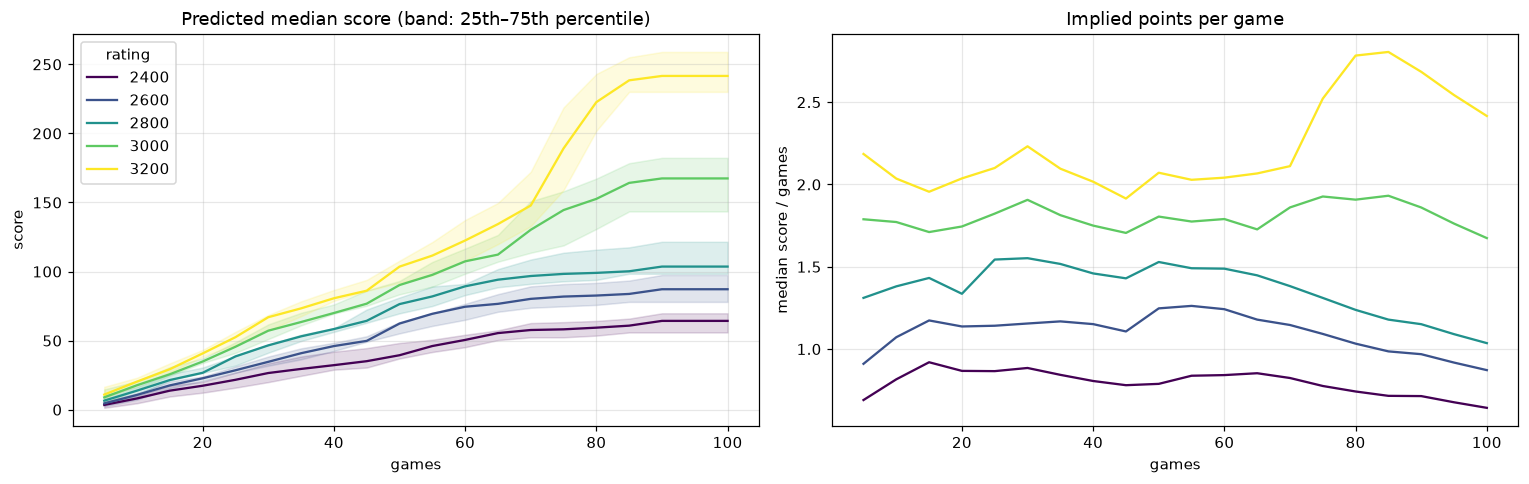

median pace: 0.57 games per minute


In [14]:
final = QuantileModel(SPECS['rating_all_commit']).fit(df, df['score'].to_numpy(float))

pace = (df['games'] / df['minutes'].clip(lower=1)).median()
games_grid = np.arange(5, 101, 5)
ratings = [2400, 2600, 2800, 3000, 3200]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cmap = plt.get_cmap('viridis', len(ratings))
for k, r in enumerate(ratings):
    X = pd.DataFrame({'rating_event': r, 'games': games_grid,
                      'minutes': np.minimum(games_grid / pace, 115), 'join_min': 5.0})
    Q = final.predict_quantiles(X)
    axes[0].plot(games_grid, Q[:, 2], color=cmap(k), label=f'{r}')
    axes[0].fill_between(games_grid, Q[:, 1], Q[:, 3], color=cmap(k), alpha=0.15)
    axes[1].plot(games_grid, Q[:, 2] / games_grid, color=cmap(k), label=f'{r}')
axes[0].set(xlabel='games', ylabel='score', title='Predicted median score (band: 25th–75th percentile)')
axes[1].set(xlabel='games', ylabel='median score / games', title='Implied points per game')
axes[0].legend(title='rating')
plt.tight_layout()
plt.show()
print(f'median pace: {pace:.2f} games per minute')

**The "five games, perfect record" question.** A player with a perfect record over five games has a raw points
per game near 3.6 (2, 3, then 4 per win). Their score projected over 50 games depends on the rating the model is
given, not on those five games:

In [15]:
X = pd.DataFrame({'rating_event': ratings, 'games': 50, 'minutes': min(50 / pace, 115), 'join_min': 5.0})
Q = final.predict_quantiles(X)
pd.DataFrame(Q, columns=QCOLS, index=pd.Index(ratings, name='rating')).assign(
    median_ppg=lambda t: t['q50'] / 50).round(1)

,q05,q25,q50,q75,q95,median_ppg
rating,,,,,,
2400,32.4,37.1,39.4,48.3,59.7,0.8
2600,47.4,55.2,62.4,63.4,70.7,1.2
2800,59.1,69.7,76.4,81.2,91.0,1.5
3000,73.0,83.5,90.2,93.2,100.0,1.8
3200,85.5,91.9,103.6,107.8,119.9,2.1


## 8. Findings

Read the tables above against these questions. Rerunning after a new snapshot (`python scripts/pull_snapshot.py`)
will change the numbers.

1. **Is there a ladder effect?** Section 2's first chart: for a fixed rating, does points per game fall as games
   rise? If so, a straight win ratio overrates short sessions, and this function is the right replacement.
2. **Games or minutes?** `rating_games` against `rating_minutes`. Whichever wins is what the commitment model
   should simulate.
3. **How much does the rating leak?** `rating_all_commit` against `prev_all_commit` on the same rows. The live
   API rating used in production should land between them.
4. **Do history and field help?** `form` and `field` against `rating_all_commit`. If `field` doesn't improve
   the top-N scores, leave it out: the Monte Carlo already captures field strength when it ranks.
5. **Is the distribution right?** 90% coverage near 0.90 and the calibration plots near the diagonal. If the
   upper tail is too thin, the winner probabilities will be too low for the favourites.
6. **Fair comparison.** `pre_event` against `current` in section 6. A win there means rating plus recent
   commitment already beats replaying old scores, before the full two-stage model is built.

**Next steps:** a commitment model (attendance, join time, minutes or games, from recent history), then a
Monte Carlo that combines it with this score function, run through the same walk-forward backtest as the
current model.